# At what spatial scale does a topographic network organize its units?

| | |
| --- | --- |
| **Question** | In a network trained so that nearby units respond alike (TDANN), how far apart can two units be and still respond alike, in an early and a late layer? Does a single global topography index detect this organization? |
| **Requires** | About 280 MB downloaded once from OSF (two checkpoints, two position files). CPU, a few minutes. |
| **Lessons used** | [3. Wrap a PyTorch model](../lessons/03_wrap_a_pytorch_model.ipynb), [5. Layers and regions](../lessons/05_layers_and_regions.ipynb) |

## Background

In visual cortex, neighboring neurons respond alike: orientation preference changes smoothly across primary visual cortex, with a full cycle within about a millimetre, and category preference is organized over several millimetres in ventral temporal cortex (VTC). The topographic deep artificial neural network (TDANN; Margalit et al., 2024, *Neuron*, [doi:10.1016/j.neuron.2024.04.018](https://doi.org/10.1016/j.neuron.2024.04.018)) gives every unit of a ResNet-18 a position on a simulated cortical sheet, and trains it with a self-supervised objective plus a spatial loss that rewards nearby units for responding alike.

The authors released the trained network, the same network trained with the spatial loss switched off, and the unit positions. Because both networks share the positions, the spatial loss is the only difference between them.

Brain-Score's topography metrics include `spatial_smoothness`, a single index: minus the rank correlation between the distance separating two units and the correlation of their responses, over randomly sampled pairs of units.

## Hypothesis

With the spatial loss, nearby units respond more alike than in the control network, in both layers. If the early layer is organized only over distances much shorter than the sheet, a global index computed over all pairs of units will be close to zero there, even though the organization is present.

## Method

**Networks.** TDANN ResNet-18 trained with SimCLR and the spatial loss (`isoswap_3`), and the same training with the spatial loss weight set to 0 (`isoswap_3_lw0`). Checkpoints are loaded with `weights_only=True`, which reads tensors only and does not run code stored in the file.

**Regions.** `layer2.0` stands for primary visual cortex and `layer4.1` for VTC, the assignment used in the TDANN paper. Both are recorded in one pass through a `BrainScoreModel`.

**Stimuli.** 48 full-field sine gratings (8 orientations, 3 spatial frequencies, 2 phases) and the 120 natural images used in the lessons.

**Measures.** (1) The global index `spatial_smoothness` on 3,000 randomly sampled units. (2) A local profile: within 30 randomly placed circular patches of cortex, the mean correlation between pairs of units as a function of their distance. The patch is 3 mm across in `layer2.0` (sheet 24.5 mm wide) and 10 mm in `layer4.1` (sheet 10 mm wide).

**Control.** The same responses with unit positions shuffled within each patch, which keeps every response and breaks the link between response and position. Its curve is flat at the patch's average correlation: distance no longer matters.

## Setup

Imports, the downloads from OSF, and the code that reads the checkpoints and prepares images.

In [1]:
# Keep the output short: no progress bars, no library warnings.
import warnings
from functools import partialmethod
from tqdm.auto import tqdm
import tqdm as _tqdm
for _bar in (tqdm, _tqdm.tqdm):
    _bar.__init__ = partialmethod(_bar.__init__, disable=True)
warnings.filterwarnings('ignore')
import os
os.environ['BS_INSTALL_DEPENDENCIES'] = 'no'      # every requirement is already installed

import tempfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import torch, torchvision
import matplotlib.pyplot as plt
from PIL import Image

CACHE = Path.home() / '.cache' / 'tdann'      # downloaded once
OSF = 'https://osf.io/download/'
FILES = {'spatial.torch': 'exugm', 'no_spatial_loss.torch': '8q32t',     # checkpoints (92 MB each)
         'layer2.0.npz': '279sy', 'layer4.1.npz': 'dnh7g'}                # unit positions
for name, key in FILES.items():
    if not (CACHE / name).exists():
        CACHE.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(OSF + key, CACHE / name)

def load_tdann(path):
    """TDANN checkpoints hold a torchvision ResNet-18 trunk under VISSL key names."""
    network = torchvision.models.resnet18()
    network.fc = torch.nn.Identity()
    trunk = torch.load(path, map_location='cpu', weights_only=True)['classy_state_dict']['base_model']['model']['trunk']
    network.load_state_dict({k.split('base_model.')[-1]: v for k, v in trunk.items()
                             if k.startswith('base_model') and 'fc.' not in k})
    return network.eval()

# The images are resized to 224 x 224 and normalized the way ImageNet networks expect.
TRANSFORM = torchvision.transforms.Compose([
    torchvision.transforms.Resize(224), torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def preprocess(paths):
    """Image files -> one (batch, 3, 224, 224) array."""
    return np.stack([TRANSFORM(Image.open(p).convert('RGB')).numpy() for p in paths])

## The subjects

Each network becomes a subject whose region map says which layer stands for which cortical area. Both share the released unit positions: one (x, y) point in millimetres per unit of each layer.

In [2]:
from brainscore_core import BrainScoreModel
from brainscore.model_helpers.vision_wrapper import VisionWrapper

LAYER = {'V1': 'layer2.0', 'VTC': 'layer4.1'}

def subject(path, name):
    network = load_tdann(path)
    return BrainScoreModel(
        identifier=name, model=network,
        extractor={'vision': VisionWrapper(identifier=name, model=network, preprocessing=preprocess)},
        region_layer_map=dict(LAYER))

subjects = {'spatial loss': subject(CACHE / 'spatial.torch', 'tdann-spatial'),
            'no spatial loss': subject(CACHE / 'no_spatial_loss.torch', 'tdann-no-spatial-loss')}

positions = {layer: np.load(CACHE / f'{layer}.npz')['coordinates'] for layer in ('layer2.0', 'layer4.1')}
{layer: (len(p), np.ptp(p, axis=0).round(1).tolist()) for layer, p in positions.items()}   # units, sheet size in mm

{'layer2.0': (100352, [24.5, 24.5]), 'layer4.1': (25088, [10.0, 10.0])}

## The experiment

### Stimuli

Gratings are written to image files so that both stimulus sets go through the same preprocessing.

In [3]:
from brainscore_core.supported_data_standards.brainio.stimuli import StimulusSet

folder = Path(tempfile.mkdtemp())
xx, yy = np.meshgrid(np.linspace(-1, 1, 224), np.linspace(-1, 1, 224))   # image coordinates from -1 to 1
rows = []
for o, theta in enumerate(np.linspace(0, np.pi, 8, endpoint=False)):     # 8 orientations
    for cycles in (2, 4, 8):                                              # cycles across the image
        for phase in (0, np.pi / 2):
            image = 0.5 + 0.5 * np.sin(2 * np.pi * cycles * (xx * np.cos(theta) + yy * np.sin(theta)) + phase)
            path = folder / f'grating_{o}_{cycles}_{phase:.2f}.png'
            Image.fromarray((image * 255).astype('uint8')).convert('RGB').save(path)
            rows.append({'stimulus_id': path.stem, 'image_path': str(path), 'orientation': o})
gratings = StimulusSet(rows); gratings.identifier = 'tdann-gratings-48'

# The 120 natural images used in the lessons.
assets = Path('../assets/lessons')
meta = pd.read_csv(assets / 'images.csv')
natural = StimulusSet([{'stimulus_id': f[:-4], 'image_path': str(assets / 'images' / f)} for f in meta.file])
natural.identifier = 'cifar10-lessons-120'
for stimuli in (gratings, natural):
    stimuli.stimulus_paths = dict(zip(stimuli['stimulus_id'], stimuli['image_path']))
len(gratings), len(natural)

(48, 120)

### Task

Plain viewing: each stimulus is shown once and both regions are recorded in the same pass. There is no answer to give.

### Controls

Two controls: the network trained without the spatial loss, which has the same unit positions; and, in the analysis, the spatial-loss network's responses with its unit positions shuffled.

## Run

One session per network and stimulus set, each asking for both regions.

In [4]:
from brainscore_core.streaming import BufferedSession

recordings = {}          # (network, stimulus set, region) -> assembly
for network, s in subjects.items():
    for set_name, stimuli in (('gratings', gratings), ('natural images', natural)):
        session = BufferedSession(stimulus_set=stimuli, requested_output_channels=['neural:V1', 'neural:VTC'])
        s.participate(session)
        for region in ('V1', 'VTC'):
            recordings[network, set_name, region] = session.collect(f'neural:{region}')

## Read results back

Each assembly has one row per stimulus and one column per unit. The units are flattened channel, row, column: the order the position files use, so column `j` sits at `positions[layer][j]`.

In [5]:
responses = {}
for key, assembly in recordings.items():
    values = np.asarray(assembly.values)
    region = key[2]
    assert values.shape[1] == len(positions[LAYER[region]])      # one position per unit
    responses[key] = values
{key: value.shape for key, value in responses.items()}

{('spatial loss', 'gratings', 'V1'): (48, 100352),
 ('spatial loss', 'gratings', 'VTC'): (48, 25088),
 ('spatial loss', 'natural images', 'V1'): (120, 100352),
 ('spatial loss', 'natural images', 'VTC'): (120, 25088),
 ('no spatial loss', 'gratings', 'V1'): (48, 100352),
 ('no spatial loss', 'gratings', 'VTC'): (48, 25088),
 ('no spatial loss', 'natural images', 'V1'): (120, 100352),
 ('no spatial loss', 'natural images', 'VTC'): (120, 25088)}

## Analysis

`spatial_smoothness` is Brain-Score's topography index, a function of responses and positions.

In [6]:
from brainscore.metrics.topographic import spatial_smoothness

def local_profile(values, coords, width, n_patches=30, n_bins=8, shuffle=False, seed=0):
    """Mean response correlation of unit pairs within circular patches, by distance."""
    rs = np.random.default_rng(seed)
    edges = np.linspace(0, width, n_bins + 1)
    total, count = np.zeros(n_bins), np.zeros(n_bins)
    for _ in range(n_patches):
        centre = coords[rs.integers(len(coords))]                 # a random unit is the patch centre
        inside = np.flatnonzero(np.linalg.norm(coords - centre, axis=1) < width / 2)
        inside = rs.choice(inside, min(len(inside), 1500), replace=False)   # at most 1,500 units per patch
        r, p = values[:, inside], coords[inside]
        keep = r.std(axis=0) > 1e-6                               # units that respond to at least one stimulus
        r, p = r[:, keep], p[keep]
        if shuffle:
            p = rs.permutation(p)
        upper = np.triu_indices(len(p), 1)                        # each pair of units once
        corr = np.corrcoef(r.T)[upper]
        dist = np.linalg.norm(p[:, None] - p[None], axis=2)[upper]
        b = np.digitize(dist, edges) - 1                          # distance bin of each pair
        ok = (b >= 0) & (b < n_bins)
        np.add.at(total, b[ok], corr[ok]); np.add.at(count, b[ok], 1)
    return (edges[:-1] + edges[1:]) / 2, total / np.maximum(count, 1)

## Results

### The global index

`spatial_smoothness` on 3,000 randomly sampled units, the same units for both networks, with the positions-shuffled control.

In [7]:
rng = np.random.default_rng(0)
sample = {region: rng.choice(len(positions[LAYER[region]]), 3000, replace=False) for region in LAYER}
rows = []
for (network, set_name, region), values in responses.items():
    units = sample[region]
    r, p = values[:, units], positions[LAYER[region]][units]
    keep = r.std(axis=0) > 1e-6                     # units that respond to at least one stimulus
    rows.append({'stimuli': set_name, 'region': region, 'network': network,
                 'index': spatial_smoothness(r[:, keep], p[keep]),
                 'shuffled positions': spatial_smoothness(r[:, keep], rng.permutation(p[keep]))})
global_index = pd.DataFrame(rows).set_index(['stimuli', 'region', 'network']).sort_index()
global_index.round(3)

index  shuffled positions
stimuli        region network                                   
gratings       V1     no spatial loss -0.001              -0.001
                      spatial loss    -0.000              -0.001
               VTC    no spatial loss  0.010              -0.001
                      spatial loss     0.239              -0.006
natural images V1     no spatial loss  0.005              -0.001
                      spatial loss    -0.002               0.000
               VTC    no spatial loss  0.004               0.000
                      spatial loss     0.216               0.000

### The local profile

Within small patches, the correlation between two units' responses as a function of the distance between them.

In [8]:
WIDTH = {'V1': 3.0, 'VTC': 10.0}     # patch width in mm
profiles = {}
for (network, set_name, region), values in responses.items():
    coords = positions[LAYER[region]]
    profiles[network, set_name, region] = local_profile(values, coords, WIDTH[region])
    if network == 'spatial loss':
        profiles['shuffled positions', set_name, region] = local_profile(values, coords, WIDTH[region], shuffle=True)

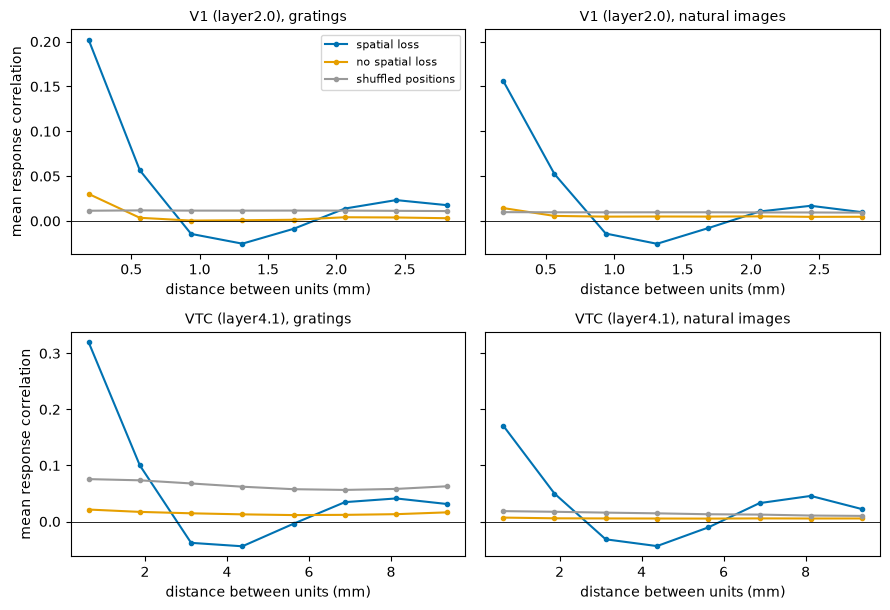

In [9]:
colors = {'spatial loss': '#0072B2', 'no spatial loss': '#E69F00', 'shuffled positions': '0.6'}
fig, axes = plt.subplots(2, 2, figsize=(9, 6.2), sharey='row')
for row, region in enumerate(('V1', 'VTC')):
    for col, set_name in enumerate(('gratings', 'natural images')):
        ax = axes[row, col]
        for network in colors:
            distance, corr = profiles[network, set_name, region]
            ax.plot(distance, corr, '-o', ms=3, color=colors[network], label=network)
        ax.axhline(0, color='k', lw=0.6)
        ax.set_title(f'{region} ({LAYER[region]}), {set_name}', fontsize=10)
        ax.set_xlabel('distance between units (mm)')
        if col == 0:
            ax.set_ylabel('mean response correlation')
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

In [10]:
nearest = {key: profile[1][0] for key, profile in profiles.items()}
pd.Series(nearest).unstack(0).round(3)        # correlation of the closest pairs in each patch

no spatial loss  shuffled positions  spatial loss
gratings       V1             0.030               0.011         0.202
               VTC            0.021               0.076         0.320
natural images V1             0.014               0.010         0.156
               VTC            0.007               0.019         0.171

With the spatial loss, the closest units in both layers respond far more alike than in the control network or with shuffled positions, for gratings and natural images alike. The correlation then falls below zero, at about 1.3 mm in `layer2.0` and 4 mm in `layer4.1`, before recovering: units a map's half-cycle apart prefer different stimuli, as in a periodic map. The global index, computed over pairs spread across the whole sheet, detects the `layer4.1` organization (about 0.2) but is close to zero for `layer2.0`, where the organization is confined to the first millimetre.

## Conclusion and limits

The spatial loss organizes both layers, at different scales: sub-millimetre in the layer that stands for V1, several millimetres in the layer that stands for VTC. These scales resemble the ones described above for cortex, which is what the network was trained to produce. The control network, with the same positions, shows no such organization, so the positions alone do not create it.

A single global index summarizes organization over the whole sheet and can miss organization confined to short distances. Any comparison of topography between models, or with cortex, should state the spatial scale it measures.

Limits: one training seed per network; 48 gratings and 120 small natural images, upsampled from 32 by 32 pixels; correlations computed on these stimuli only; 30 patches per layer. The comparison with cortex here is qualitative; measuring alignment with recorded cortical maps needs recordings with cortical positions.

[Lessons](../lessons/) · [Documentation](../../docs/README.md)